# House Price Prediction

### Project Overview
* The real estate market is influenced by numerous factors such as location, property size, construction quality, neighborhood, garage capacity, basement area, and overall condition of the house. Accurately estimating house prices is important for buyers, sellers, investors, and real estate companies to make informed decisions.
* The objective of this project is to develop a machine learning model capable of predicting house sale prices based on various property characteristics. The project also aims to identify the key factors that influence housing prices and provide recommendations to customers based on their budget and preferences.

### Business Problem
* Determining a fair market value for a property can be challenging due to the large number of factors involved. Traditional valuation methods often rely heavily on human expertise and may not consistently capture complex relationships between property features and market prices.

### Dataset Description
The dataset contains residential property information including:
* Property dimensions and lot size
* Neighborhood and zoning information
* Construction quality and condition
* Basement and garage details
* Number of rooms and bathrooms
* Sale conditions and transaction details
* Final sale price (target variable)

The target variable for prediction is:
* SalePrice – The final sale price of the property in dollars.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("data.csv")

In [3]:
print("\n================ FIRST 5 ROWS ================\n")
print(df.head())

print("\n================ DATASET SHAPE ================\n")
print(df.shape)

print("\n================ DATA TYPES ================\n")
print(df.dtypes)

print("\n================ STATISTICAL SUMMARY ================\n")
print(df.describe())


================ FIRST 5 ROWS ================

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType 


================ MISSING VALUES ================

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


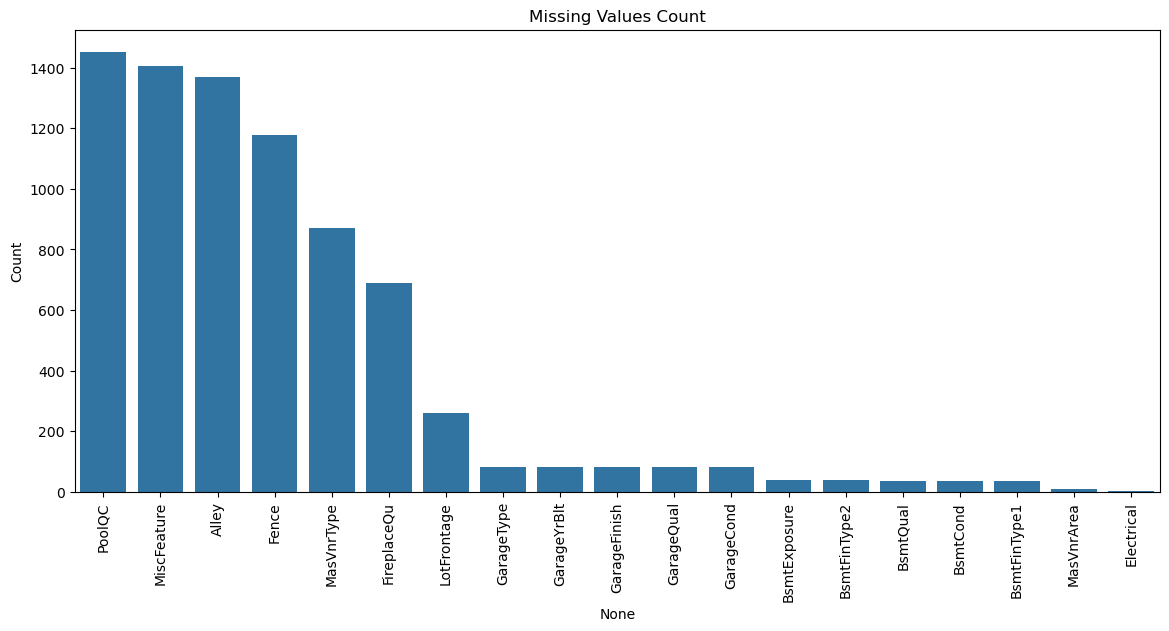

In [4]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_values = missing_values.sort_values(
    ascending=False
)

print("\n================ MISSING VALUES ================\n")
print(missing_values)

plt.figure(figsize=(14,6))

sns.barplot(
    x=missing_values.index,
    y=missing_values.values
)

plt.xticks(rotation=90)

plt.title("Missing Values Count")

plt.ylabel("Count")

plt.show()

In [5]:
num_cols = df.select_dtypes(include=np.number).columns

cat_cols = df.select_dtypes(exclude=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\n================ NULL VALUES AFTER CLEANING ================\n")
print(df.isnull().sum().sum())


================ NULL VALUES AFTER CLEANING ================

0


## EDA Observations
* The distribution of SalePrice is slightly right-skewed, indicating the presence of high-value properties that may act as outliers.
* Several features contained missing values, particularly those related to basements, garages, pools, and alley access. Appropriate imputation techniques were applied to preserve valuable information.
* Correlation analysis revealed that OverallQual, GrLivArea, GarageCars, TotalBsmtSF, and GarageArea have strong positive relationships with SalePrice.
* Houses with higher overall quality ratings consistently achieved significantly higher sale prices compared to lower-quality properties.
* Premium neighborhoods exhibited substantially higher average sale prices than other areas, highlighting the importance of location in property valuation.
* Larger living areas generally corresponded to higher property prices, although a few extreme outliers were observed.
* Feature engineering created additional variables such as HouseAge, TotalBathrooms, and TotalPorchSF, which helped capture important property characteristics more effectively.

In [6]:
df['HouseAge'] = df['YrSold'] - df['YearBuilt']

df['TotalBathrooms'] = (
    df['FullBath']
    + (0.5 * df['HalfBath'])
    + df['BsmtFullBath']
    + (0.5 * df['BsmtHalfBath'])
)

df['TotalPorchSF'] = (
    df['OpenPorchSF']
    + df['EnclosedPorch']
    + df['3SsnPorch']
    + df['ScreenPorch']
)

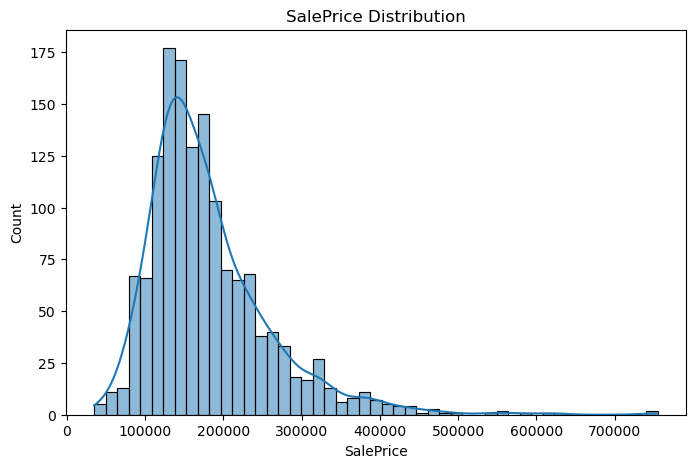

In [7]:
plt.figure(figsize=(8,5))

sns.histplot(df['SalePrice'], kde=True)

plt.title("SalePrice Distribution")

plt.show()

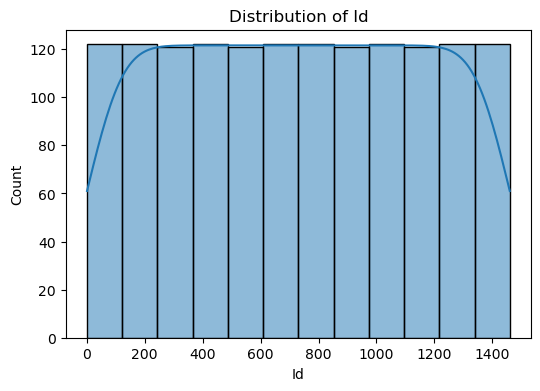

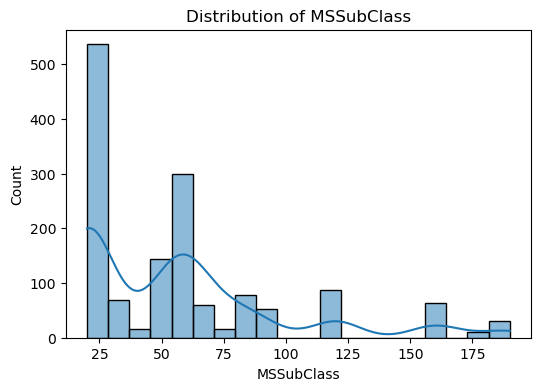

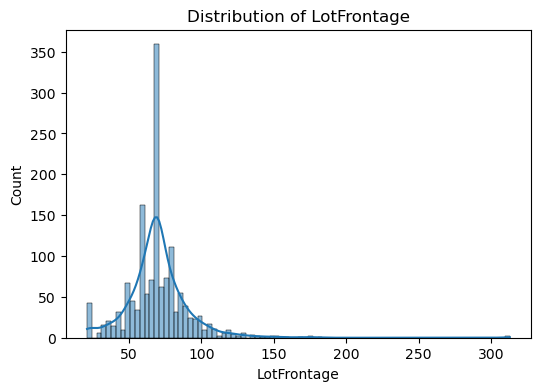

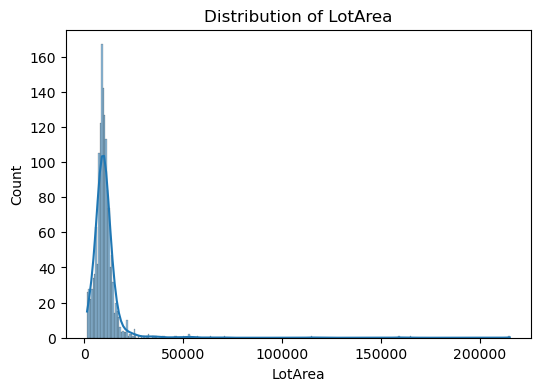

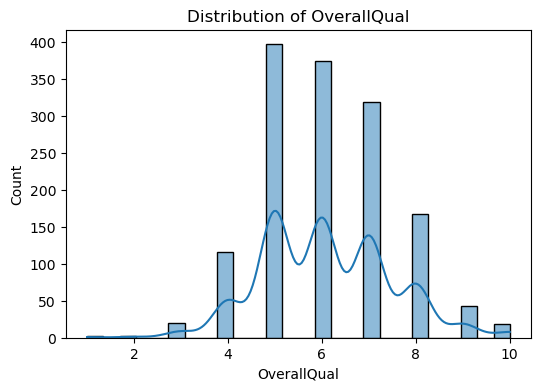

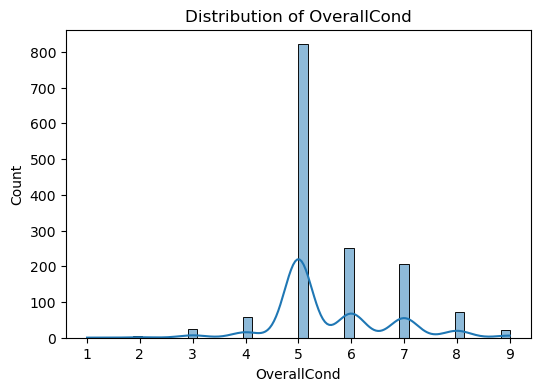

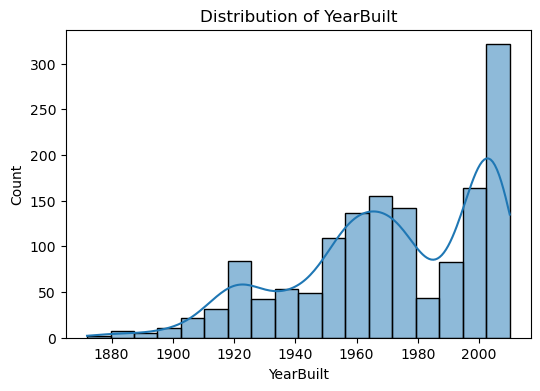

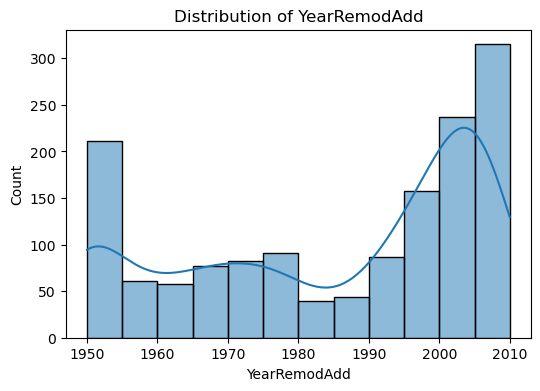

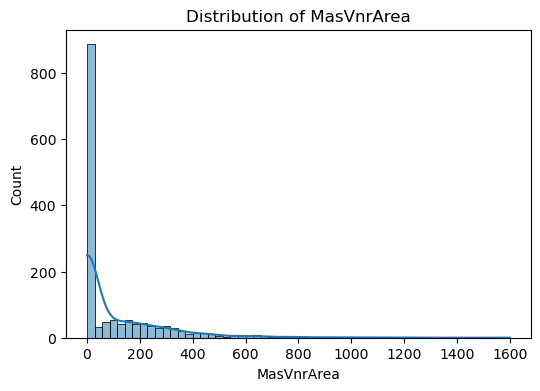

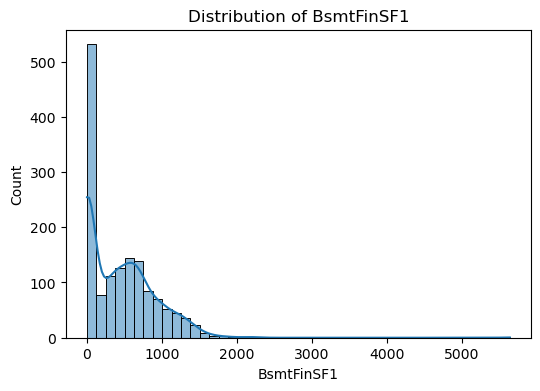

In [8]:
numerical_features = df.select_dtypes(include=np.number).columns

for col in numerical_features[:10]:

    plt.figure(figsize=(6,4))

    sns.histplot(df[col], kde=True)

    plt.title(f"Distribution of {col}")

    plt.show()

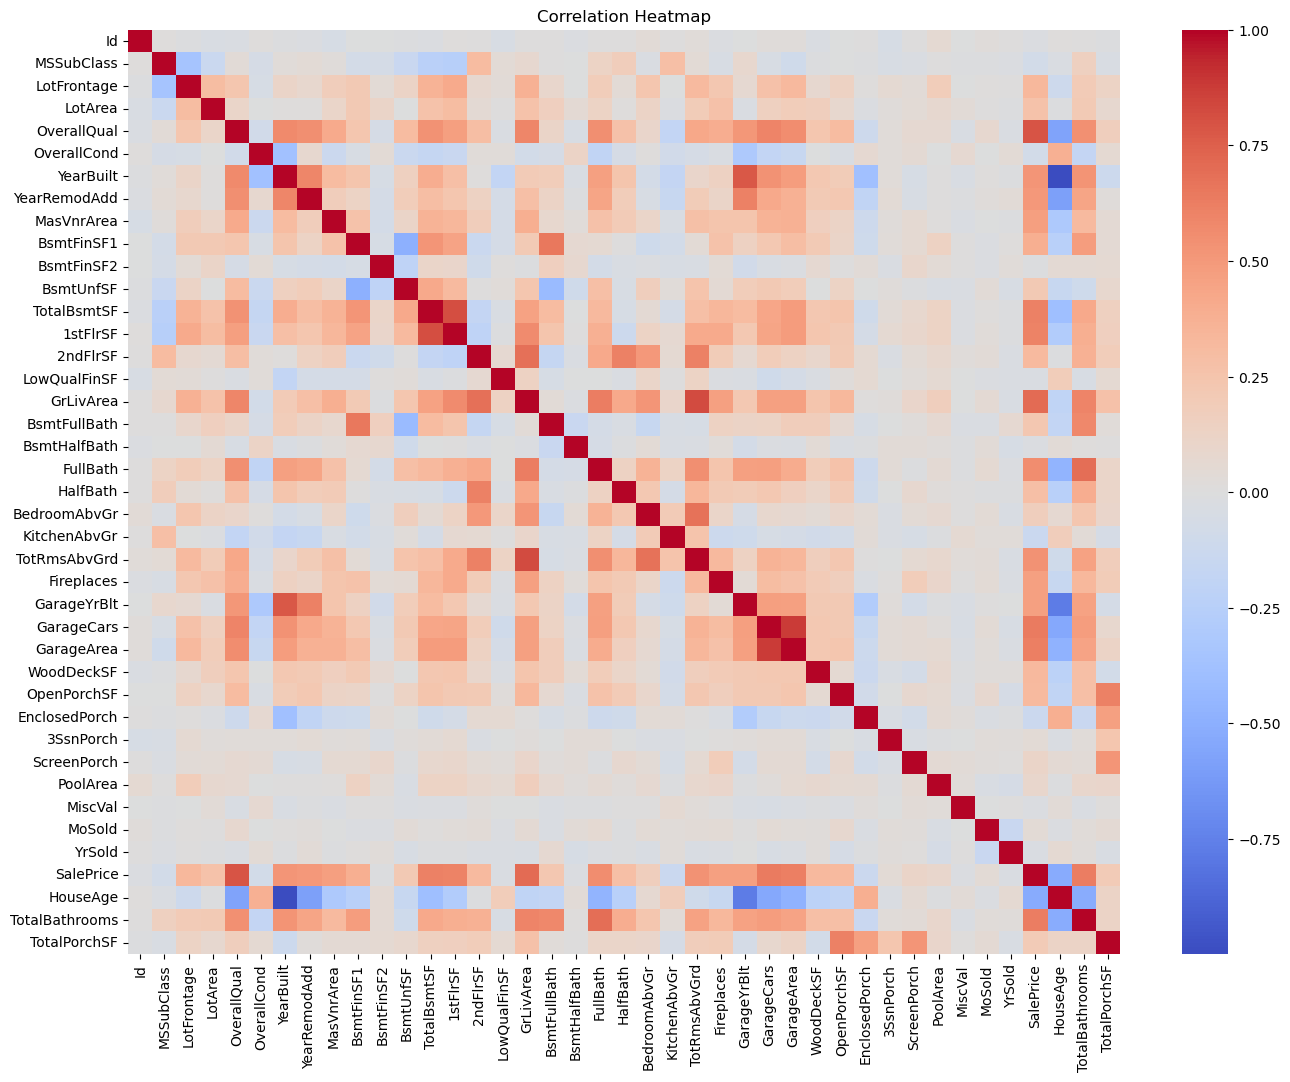

In [9]:
plt.figure(figsize=(16,12))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

In [10]:
corr = df.corr(numeric_only=True)['SalePrice']

corr = corr.sort_values(ascending=False)

print("\n================ TOP CORRELATED FEATURES ================\n")
print(corr.head(15))


================ TOP CORRELATED FEATURES ================

SalePrice         1.000000
OverallQual       0.790982
GrLivArea         0.708624
GarageCars        0.640409
TotalBathrooms    0.631731
GarageArea        0.623431
TotalBsmtSF       0.613581
1stFlrSF          0.605852
FullBath          0.560664
TotRmsAbvGrd      0.533723
YearBuilt         0.522897
YearRemodAdd      0.507101
MasVnrArea        0.472614
Fireplaces        0.466929
GarageYrBlt       0.466754
Name: SalePrice, dtype: float64


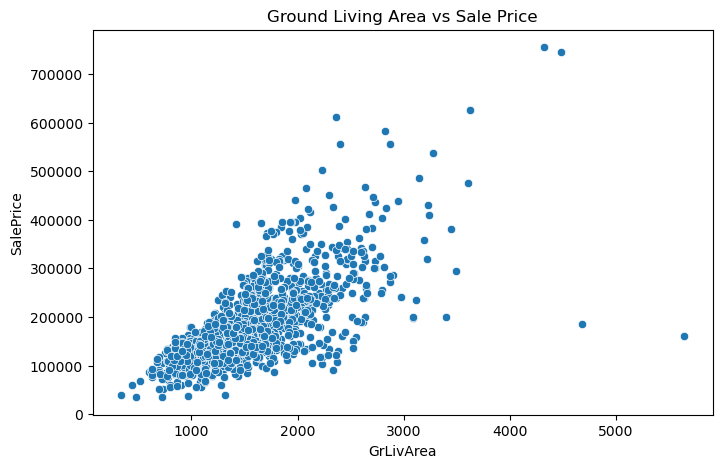

In [11]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df['GrLivArea'],
    y=df['SalePrice']
)

plt.title("Ground Living Area vs Sale Price")

plt.show()

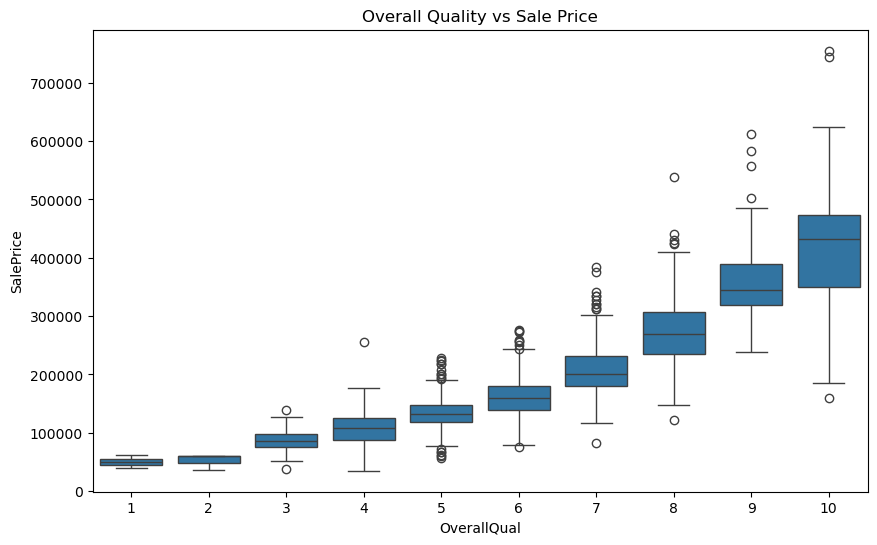


Average Price based on Overall Quality:

OverallQual
1      50150.000000
2      51770.333333
3      87473.750000
4     108420.655172
5     133523.347607
6     161603.034759
7     207716.423197
8     274735.535714
9     367513.023256
10    438588.388889
Name: SalePrice, dtype: float64


In [12]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x='OverallQual',
    y='SalePrice',
    data=df
)

plt.title("Overall Quality vs Sale Price")

plt.show()

quality_price = df.groupby(
    'OverallQual'
)['SalePrice'].mean()

print("\nAverage Price based on Overall Quality:\n")
print(quality_price)

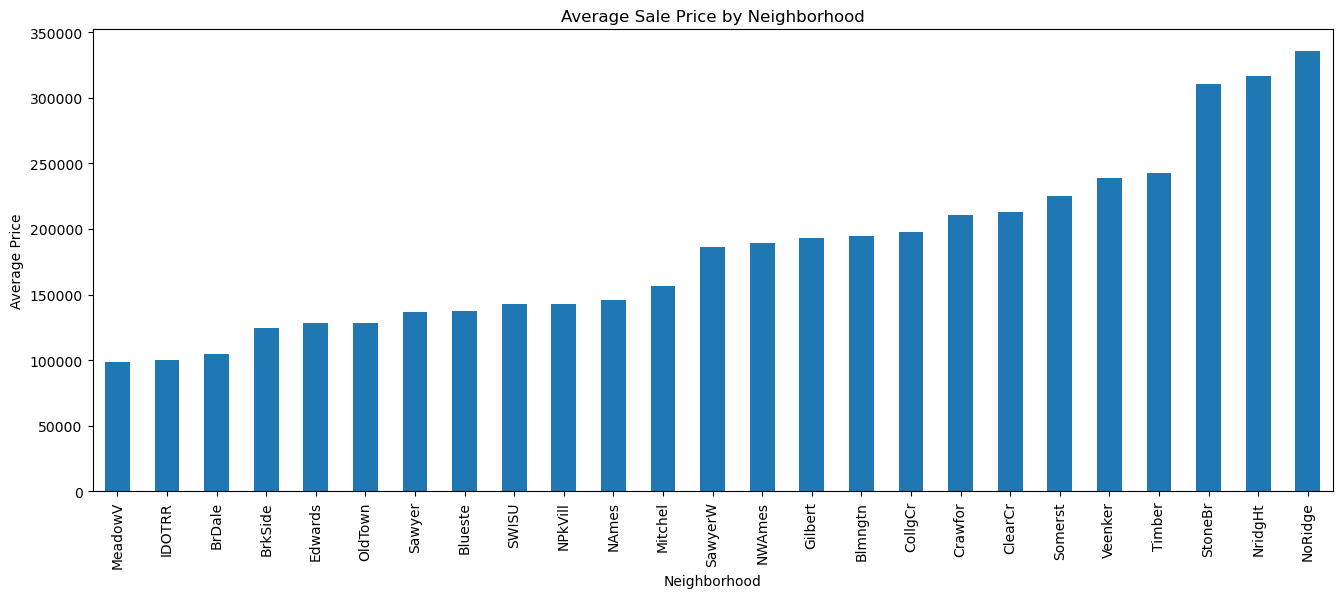


Average Sale Price by Neighborhood:

Neighborhood
MeadowV     98576.470588
IDOTRR     100123.783784
BrDale     104493.750000
BrkSide    124834.051724
Edwards    128219.700000
OldTown    128225.300885
Sawyer     136793.135135
Blueste    137500.000000
SWISU      142591.360000
NPkVill    142694.444444
NAmes      145847.080000
Mitchel    156270.122449
SawyerW    186555.796610
NWAmes     189050.068493
Gilbert    192854.506329
Blmngtn    194870.882353
CollgCr    197965.773333
Crawfor    210624.725490
ClearCr    212565.428571
Somerst    225379.837209
Veenker    238772.727273
Timber     242247.447368
StoneBr    310499.000000
NridgHt    316270.623377
NoRidge    335295.317073
Name: SalePrice, dtype: float64


In [13]:
plt.figure(figsize=(16,6))

avg_price = df.groupby(
    'Neighborhood'
)['SalePrice'].mean().sort_values()

avg_price.plot(kind='bar')

plt.title("Average Sale Price by Neighborhood")

plt.ylabel("Average Price")

plt.show()

print("\nAverage Sale Price by Neighborhood:\n")
print(avg_price)

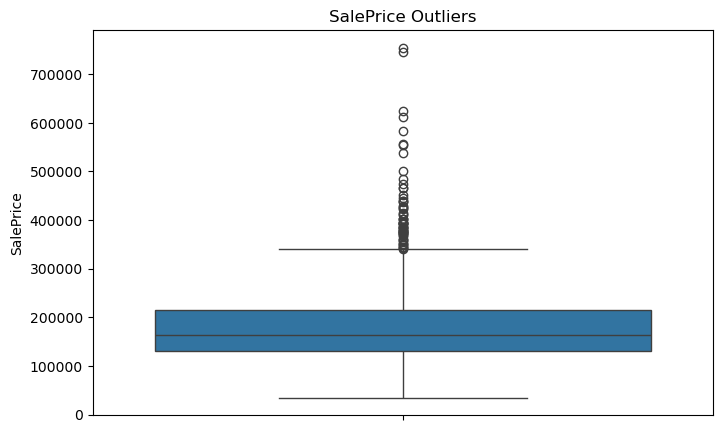

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(df['SalePrice'])

plt.title("SalePrice Outliers")

plt.show()

In [15]:
df = df[df['SalePrice'] < 500000]

In [16]:
df = pd.get_dummies(
    df,
    drop_first=True
)

In [17]:
X = df.drop('SalePrice', axis=1)

y = df['SalePrice']

In [18]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

In [20]:
models = {

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

In [21]:
results = []

for name, model in models.items():

    print(f"\n================ {name} ================\n")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    mse = mean_squared_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        y_pred
    )

    cv_score = cross_val_score(
        model,
        X_scaled,
        y,
        cv=5,
        scoring='r2'
    ).mean()

    print("MAE :", mae)

    print("RMSE:", rmse)

    print("R2 Score:", r2)

    print("Cross Validation Score:", cv_score)

    results.append([
        name,
        mae,
        rmse,
        r2,
        cv_score
    ])


================ Linear Regression ================

MAE : 18326.773377316935
RMSE: 45881.93876687118
R2 Score: 0.5664114418767625
Cross Validation Score: 0.7015022658067032

================ Decision Tree ================

MAE : 24947.3264604811
RMSE: 35353.43026795759
R2 Score: 0.7425710359960895
Cross Validation Score: 0.7138431376087475

================ Random Forest ================

MAE : 16001.594914089348
RMSE: 23324.980144274617
R2 Score: 0.887943550781668
Cross Validation Score: 0.8692937684058784

================ Gradient Boosting ================

MAE : 15306.691621655438
RMSE: 22142.518105926163
R2 Score: 0.8990169907879577
Cross Validation Score: 0.897463872791483


## Model Comparison Explanation
* Model Evaluation Strategy

To identify the most suitable model for production deployment, multiple regression algorithms were trained and evaluated.

The following performance metrics were used:

* Mean Absolute Error (MAE)

MAE measures the average difference between actual and predicted house prices.

Lower MAE values indicate more accurate predictions.

* Root Mean Squared Error (RMSE)

RMSE penalizes larger prediction errors more heavily than MAE.

A lower RMSE indicates better predictive performance and fewer large estimation errors.

* R² Score

R² Score measures the proportion of variance in house prices explained by the model.

Values closer to 1 indicate stronger predictive capability.

* Cross-Validation Score

Cross-validation was used to assess how well the model generalizes to unseen data and to reduce the risk of overfitting.

In [22]:
results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'MAE',
        'RMSE',
        'R2 Score',
        'Cross Validation Score'
    ]
)

print("\n================ MODEL COMPARISON ================\n")

print(results_df)


================ MODEL COMPARISON ================

               Model           MAE          RMSE  R2 Score  \
0  Linear Regression  18326.773377  45881.938767  0.566411   
1      Decision Tree  24947.326460  35353.430268  0.742571   
2      Random Forest  16001.594914  23324.980144  0.887944   
3  Gradient Boosting  15306.691622  22142.518106  0.899017   

   Cross Validation Score  
0                0.701502  
1                0.713843  
2                0.869294  
3                0.897464  


In [23]:
best_model = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

print("\n================ BEST MODEL ================\n")

print(best_model.head(1))


================ BEST MODEL ================

               Model           MAE          RMSE  R2 Score  \
3  Gradient Boosting  15306.691622  22142.518106  0.899017   

   Cross Validation Score  
3                0.897464  


In [26]:
print("\n================ HYPERPARAMETER TUNING ================\n")

param_grid = {

    'n_estimators': [100, 200],

    'max_depth': [10, 20, None],

    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(

    RandomForestRegressor(
        random_state=42
    ),

    param_grid,

    cv=3,

    scoring='r2',

    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_

print("Best Parameters:\n")

print(grid_search.best_params_)


================ HYPERPARAMETER TUNING ================

Best Parameters:

{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}



================ FEATURE IMPORTANCE ================

           Feature  Importance
4      OverallQual    0.581850
16       GrLivArea    0.101602
9       BsmtFinSF1    0.040789
12     TotalBsmtSF    0.032598
13        1stFlrSF    0.023901
27      GarageArea    0.023091
38  TotalBathrooms    0.022103
3          LotArea    0.018626
26      GarageCars    0.017083
6        YearBuilt    0.007932
14        2ndFlrSF    0.006721
37        HouseAge    0.006405
2      LotFrontage    0.006060
7     YearRemodAdd    0.005993
19        FullBath    0.005513


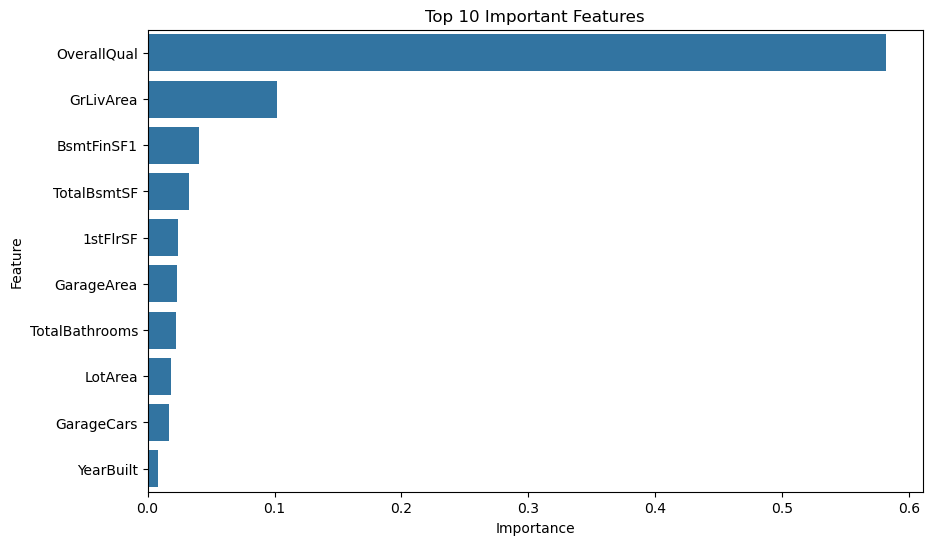

In [27]:
importance = best_rf.feature_importances_

feature_importance = pd.DataFrame({

    'Feature': X.columns,

    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\n================ FEATURE IMPORTANCE ================\n")

print(feature_importance.head(15))

plt.figure(figsize=(10,6))

sns.barplot(

    x=feature_importance['Importance'].head(10),

    y=feature_importance['Feature'].head(10)
)

plt.title("Top 10 Important Features")

plt.show()

In [28]:
print("\n================ CUSTOMER RECOMMENDATIONS ================\n")

budget = 200000

recommended_houses = df[
    df['SalePrice'] <= budget
]

print("\nAffordable Houses:\n")

print(
    recommended_houses[
        [
            'SalePrice',
            'OverallQual',
            'GrLivArea',
            'GarageCars'
        ]
    ].head(10)
)

if 'Neighborhood_NAmes' in df.columns:

    area_houses = df[
        df['Neighborhood_NAmes'] == 1
    ]

    print("\nHouses in NAmes Area:\n")

    print(
        area_houses[
            [
                'SalePrice',
                'OverallQual',
                'GrLivArea'
            ]
        ].head(10)
    )


================ CUSTOMER RECOMMENDATIONS ================


Affordable Houses:

    SalePrice  OverallQual  GrLivArea  GarageCars
1      181500            6       1262           2
3      140000            7       1717           3
5      143000            5       1362           2
7      200000            7       2090           2
8      129900            7       1774           2
9      118000            5       1077           1
10     129500            5       1040           1
12     144000            5        912           1
14     157000            6       1253           1
15     132000            7        854           2

Houses in NAmes Area:

    SalePrice  OverallQual  GrLivArea
14     157000            6       1253
16     149000            6       1004
19     139000            5       1339
26     134800            5        900
28     207500            5       1600
33     165500            5       1700
37     153000            5       1297
38     109000            5       1057
40

In [29]:
print("\n================ SAMPLE PREDICTION ================\n")

sample_house = X.iloc[[0]]

sample_scaled = scaler.transform(sample_house)

predicted_price = best_rf.predict(
    sample_scaled
)

print("Predicted House Price:")

print(predicted_price[0])


================ SAMPLE PREDICTION ================

Predicted House Price:
207718.33193798448


In [30]:
results_df.to_csv(
    "house_price_model_results.csv",
    index=False
)

feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

## Challenges Faced 
| Challenge                      | Technique Used                   | Reason                         |
| ------------------------------ | -------------------------------- | ------------------------------ |
| Missing Values                 | Median/Mode Imputation           | Preserve data quality          |
| Categorical Features           | One-Hot Encoding                 | Convert text to numerical form |
| Outliers                       | Detection and Removal            | Improve model accuracy         |
| High Dimensionality            | Feature Importance Analysis      | Identify useful features       |
| Non-Linear Relationships       | Random Forest, Gradient Boosting | Capture complex patterns       |
| Overfitting                    | Cross-Validation, GridSearchCV   | Improve generalization         |
| Limited Feature Representation | Feature Engineering              | Enhance predictive power       |
| Model Selection                | Multiple Model Comparison        | Identify best-performing model |


# Conclusion

The House Price Prediction project successfully developed and evaluated multiple machine learning models for estimating house prices.

### Important Factors Influencing House Prices
Feature importance analysis identified the following variables as the strongest contributors to property value:
* Overall Quality
* Ground Living Area
* Neighborhood
* Garage Capacity
* Basement Area
* Total Bathrooms
* House Age

### Business Impact
The developed model can be used to:
* Assist home buyers in estimating fair property prices.
* Help sellers determine competitive listing prices.
* Support real estate agencies in automating property valuation.
* Enable investors to identify profitable investment opportunities.

### Project Limitations
Although the model achieved strong predictive performance, several limitations should be considered:
* Predictions are based on historical data and may not reflect sudden market changes.
* External economic factors such as interest rates and inflation are not included.
* Rare property types may be underrepresented in the dataset.

### Future Improvements
* Implementing advanced algorithms such as XGBoost and CatBoost.
* Integrating real-time market and economic data.
* Deploying the model as a web application using Streamlit or Flask.
* Building a more sophisticated recommendation engine for personalized property suggestions.